# Task 3: House Price Prediction using Simple & Multiple Linear Regression
**Author:** Pranav  
**Role:** Senior Machine Learning Engineer & Data Scientist  
**Dataset:** Housing.csv (545 properties, 13 attributes)  
**Target Variable:** `price` (Continuous Numerical)

---

## 1. Project Overview & Theoretical Foundation

Linear Regression is one of the foundational supervised machine learning algorithms used for predictive modeling of continuous quantitative outcomes. Given a set of explanatory features (independent variables), linear regression models the target variable (dependent variable) as a linear combination of inputs weighted by learnable parameters (coefficients), plus an error term.

### 1.1 Simple Linear Regression
Simple Linear Regression investigates the relationship between a single independent continuous predictor $X$ and the dependent continuous target $Y$:

$$Y = \beta_0 + \beta_1 X + \varepsilon$$

Where:
- $Y$: Dependent target variable (`price`)
- $X$: Independent explanatory variable (`area`)
- $\beta_0$: Intercept (value of $Y$ when $X = 0$)
- $\beta_1$: Regression slope (rate of change in $Y$ per unit change in $X$)
- $\varepsilon$: Random disturbance / error term with $E[\varepsilon] = 0$

### 1.2 Multiple Linear Regression
Multiple Linear Regression generalizes this formulation to $p$ independent features:

$$Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_p X_p + \varepsilon = \beta_0 + \sum_{i=1}^{p} \beta_i X_i + \varepsilon$$

Where each $\beta_i$ represents the **partial regression coefficient**, measuring the expected change in $Y$ for a one-unit change in $X_i$, holding all other predictors constant (*ceteris paribus*).

### 1.3 Optimization: Ordinary Least Squares (OLS)
The regression parameters are estimated by minimizing the **Residual Sum of Squares (RSS)**:

$$\text{RSS}(\beta) = \sum_{i=1}^{m} (y_i - \hat{y}_i)^2 = \sum_{i=1}^{m} \left(y_i - \left(\beta_0 + \sum_{j=1}^{p} \beta_j x_{ij}\right)\right)^2$$

### 1.4 Project Workflow
1. **Environment Setup & Library Ingestion**
2. **Dataset Loading & Exploratory Schema Inspection**
3. **Exploratory Data Analysis (EDA) & Visual Pattern Extraction**
4. **Data Preprocessing & Feature Encoding Architecture**
5. **Leakage-Free Train-Test Splitting (80/20)**
6. **Simple Linear Regression Training & Geometric Line Fitting**
7. **Multiple Linear Regression Pipeline Formulation & Training**
8. **Mathematical Regression Equation & Coefficient Interpretation**
9. **Rigorous Evaluation Metric Computation (MAE, MSE, RMSE, R²)**
10. **Actual vs. Predicted Performance Visualization**
11. **Residual Diagnostics & Statistical Distribution Examination**
12. **Linear Regression Assumption Verification (VIF, Q-Q, Homoscedasticity)**
13. **Comprehensive Model Comparison & Trade-off Analysis**
14. **Production Inference Demonstration on Unseen Query**
15. **Artifact Serialization & Evaluation Report Export**


## 2. Environment Setup & Library Imports

In this section, we import core data science and machine learning packages. All operations are structured to prevent data leakage and ensure reproducible execution.

In [1]:
# Core scientific computing and data analysis libraries
import os
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical diagnostics
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Scikit-learn preprocessing, modeling, and evaluation modules
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Model serialization
import joblib

# Global plot aesthetic configuration
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['figure.autolayout'] = True
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Define project directories
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET_PATH = BASE_DIR / "dataset" / "Housing.csv"
VIS_DIR = BASE_DIR / "outputs" / "visualizations"
MODELS_DIR = BASE_DIR / "outputs" / "models"
REPORTS_DIR = BASE_DIR / "outputs" / "reports"

for d in [VIS_DIR, MODELS_DIR, REPORTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"Project Base Directory: {BASE_DIR}")
print(f"Dataset Path: {DATASET_PATH} (Exists: {DATASET_PATH.exists()})")


Project Base Directory: /Users/pranavagneesh/Desktop/linear-regression-house-price-prediction
Dataset Path: /Users/pranavagneesh/Desktop/linear-regression-house-price-prediction/dataset/Housing.csv (Exists: True)


## 3. Load & Explore Dataset

We load `Housing.csv` and inspect its shape, attributes, data types, missing records, and descriptive statistics. We verify the schema rather than making arbitrary assumptions.

In [2]:
# Ingest dataset
df = pd.read_csv(DATASET_PATH)

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("First 5 Observations:")
display(df.head())

print("\nLast 5 Observations:")
display(df.tail())


Dataset Dimensions: 545 rows, 13 columns

First 5 Observations:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



Last 5 Observations:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
544,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished


In [3]:
# Column Names and Data Types
print("Schema Information:")
df.info()

print("\nDescriptive Statistics for Numerical Features:")
display(df.describe().T)

print("\nMissing Values Count:")
display(df.isnull().sum())

print(f"\nDuplicate Records Count: {df.duplicated().sum()}")


Schema Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

Descriptive Statistics for Numerical Features:


,count,mean,std,min,25%,50%,75%,max
price,545.0,4.766729e+06,1.870440e+06,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,545.0,5.150541e+03,2.170141e+03,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,545.0,2.965138e+00,7.380639e-01,1.0,2.0,3.0,3.0,6.0
bathrooms,545.0,1.286239e+00,5.024696e-01,1.0,1.0,1.0,2.0,4.0
stories,545.0,1.805505e+00,8.674925e-01,1.0,1.0,2.0,2.0,4.0
parking,545.0,6.935780e-01,8.615858e-01,0.0,0.0,0.0,1.0,3.0



Missing Values Count:


price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


Duplicate Records Count: 0


In [4]:
# Classify Numerical and Categorical Features
target_col = 'price'
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop(target_col).tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print(f"Target Variable: {target_col}")
print(f"Numerical Features ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical Features ({len(categorical_cols)}): {categorical_cols}")

print("\nCategorical Unique Categories:")
for col in categorical_cols:
    print(f"  - {col}: {list(df[col].unique())}")


Target Variable: price
Numerical Features (5): ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Categorical Features (7): ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']

Categorical Unique Categories:
  - mainroad: ['yes', 'no']
  - guestroom: ['no', 'yes']
  - basement: ['no', 'yes']
  - hotwaterheating: ['no', 'yes']
  - airconditioning: ['yes', 'no']
  - prefarea: ['yes', 'no']
  - furnishingstatus: ['furnished', 'semi-furnished', 'unfurnished']


## 4. Exploratory Data Analysis (EDA)

We explore data distributions, correlations, and relationships between predictors and house prices to understand structural trends, skewness, and potential outliers.

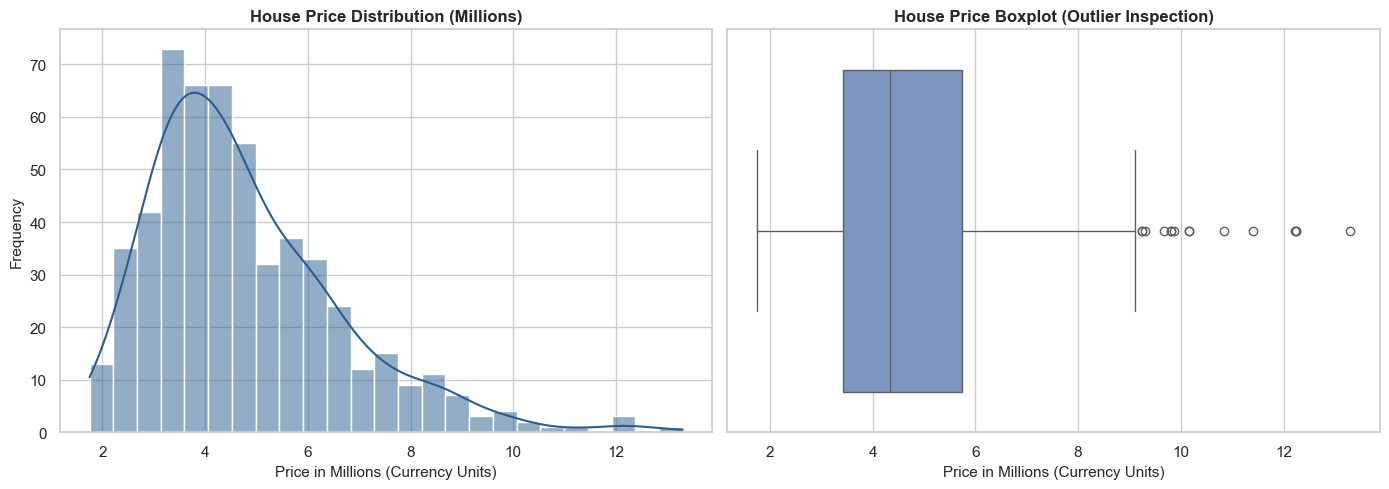

Price Skewness: 1.21 (moderate positive right skew)
Price Kurtosis: 1.96


In [5]:
# 4.1 Price and Area Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['price'] / 1e6, kde=True, ax=axes[0], color='#2b5c8f', bins=25)
axes[0].set_title('House Price Distribution (Millions)', fontweight='bold')
axes[0].set_xlabel('Price in Millions (Currency Units)')
axes[0].set_ylabel('Frequency')

sns.boxplot(x=df['price'] / 1e6, ax=axes[1], color='#7293cb')
axes[1].set_title('House Price Boxplot (Outlier Inspection)', fontweight='bold')
axes[1].set_xlabel('Price in Millions (Currency Units)')

plt.savefig(VIS_DIR / 'price_distribution.png', dpi=300)
plt.show()

print(f"Price Skewness: {df['price'].skew():.2f} (moderate positive right skew)")
print(f"Price Kurtosis: {df['price'].kurtosis():.2f}")


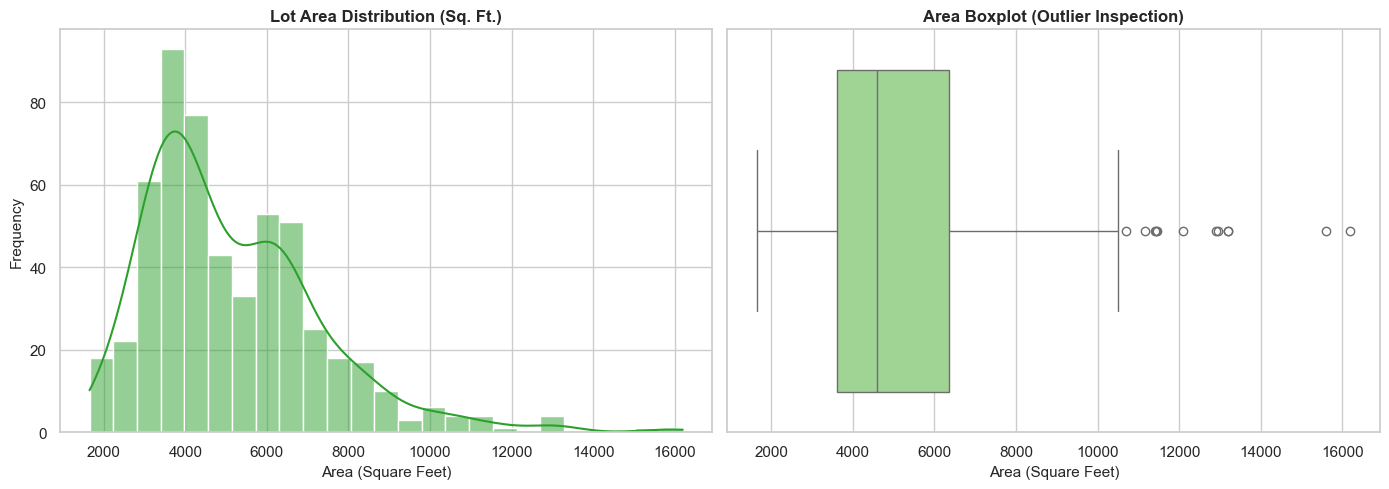

Area Skewness: 1.32
Area Kurtosis: 2.75


In [6]:
# 4.2 Area Distribution & Outlier Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['area'], kde=True, ax=axes[0], color='#2ca02c', bins=25)
axes[0].set_title('Lot Area Distribution (Sq. Ft.)', fontweight='bold')
axes[0].set_xlabel('Area (Square Feet)')
axes[0].set_ylabel('Frequency')

sns.boxplot(x=df['area'], ax=axes[1], color='#98df8a')
axes[1].set_title('Area Boxplot (Outlier Inspection)', fontweight='bold')
axes[1].set_xlabel('Area (Square Feet)')

plt.savefig(VIS_DIR / 'area_distribution.png', dpi=300)
plt.show()

print(f"Area Skewness: {df['area'].skew():.2f}")
print(f"Area Kurtosis: {df['area'].kurtosis():.2f}")


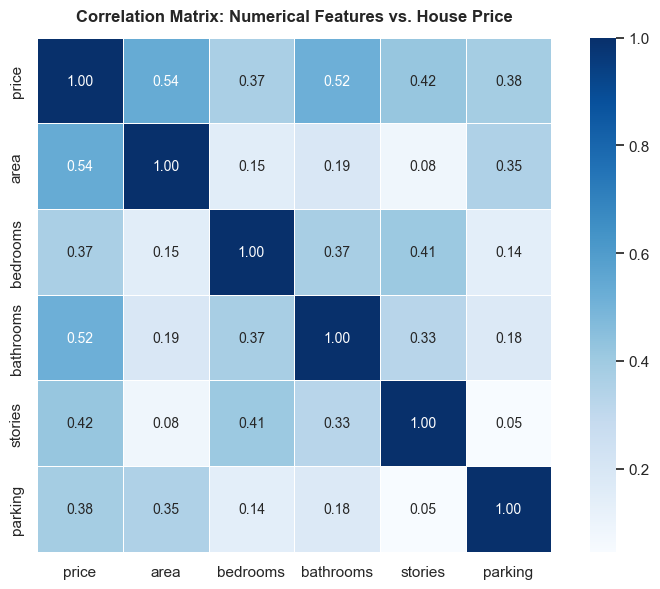

Pearson Correlations with Target Price:
price        1.000000
area         0.535997
bathrooms    0.517545
stories      0.420712
parking      0.384394
bedrooms     0.366494
Name: price, dtype: float64


In [7]:
# 4.3 Correlation Heatmap
num_with_target = [target_col] + numerical_cols
corr_matrix = df[num_with_target].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', cbar=True, square=True, linewidths=0.5)
plt.title('Correlation Matrix: Numerical Features vs. House Price', fontweight='bold', pad=12)
plt.savefig(VIS_DIR / 'correlation_heatmap.png', dpi=300)
plt.show()

print("Pearson Correlations with Target Price:")
print(corr_matrix[target_col].sort_values(ascending=False))


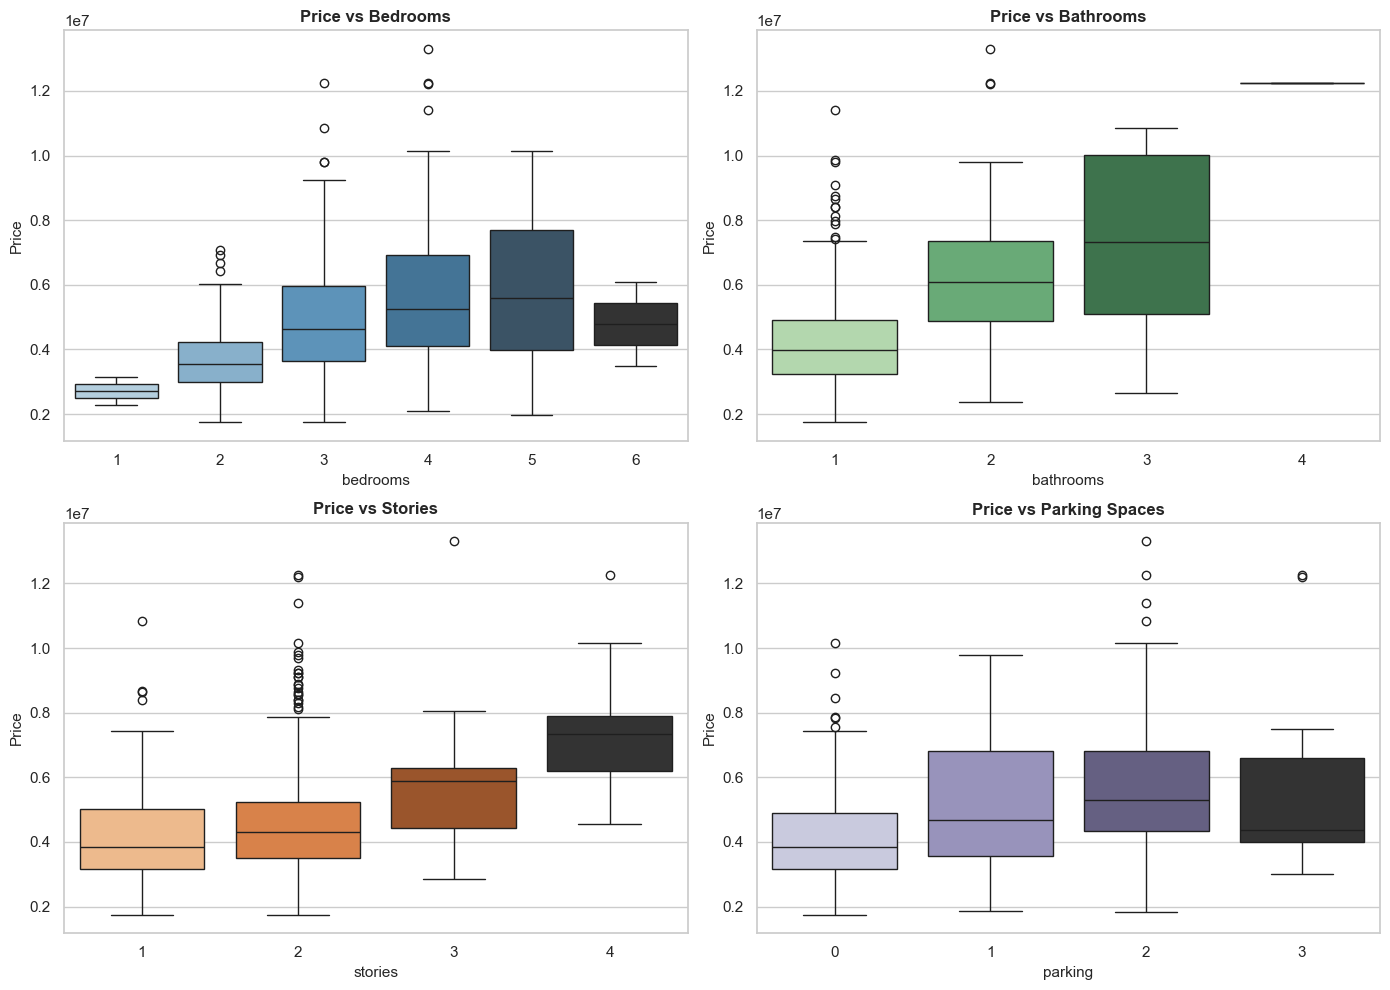

In [8]:
# 4.4 Numerical Features vs House Price
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=df, x='bedrooms', y='price', ax=axes[0, 0], palette='Blues_d', hue='bedrooms', legend=False)
axes[0, 0].set_title('Price vs Bedrooms', fontweight='bold')
axes[0, 0].set_ylabel('Price')

sns.boxplot(data=df, x='bathrooms', y='price', ax=axes[0, 1], palette='Greens_d', hue='bathrooms', legend=False)
axes[0, 1].set_title('Price vs Bathrooms', fontweight='bold')
axes[0, 1].set_ylabel('Price')

sns.boxplot(data=df, x='stories', y='price', ax=axes[1, 0], palette='Oranges_d', hue='stories', legend=False)
axes[1, 0].set_title('Price vs Stories', fontweight='bold')
axes[1, 0].set_ylabel('Price')

sns.boxplot(data=df, x='parking', y='price', ax=axes[1, 1], palette='Purples_d', hue='parking', legend=False)
axes[1, 1].set_title('Price vs Parking Spaces', fontweight='bold')
axes[1, 1].set_ylabel('Price')

plt.savefig(VIS_DIR / 'numerical_features_vs_price.png', dpi=300)
plt.show()


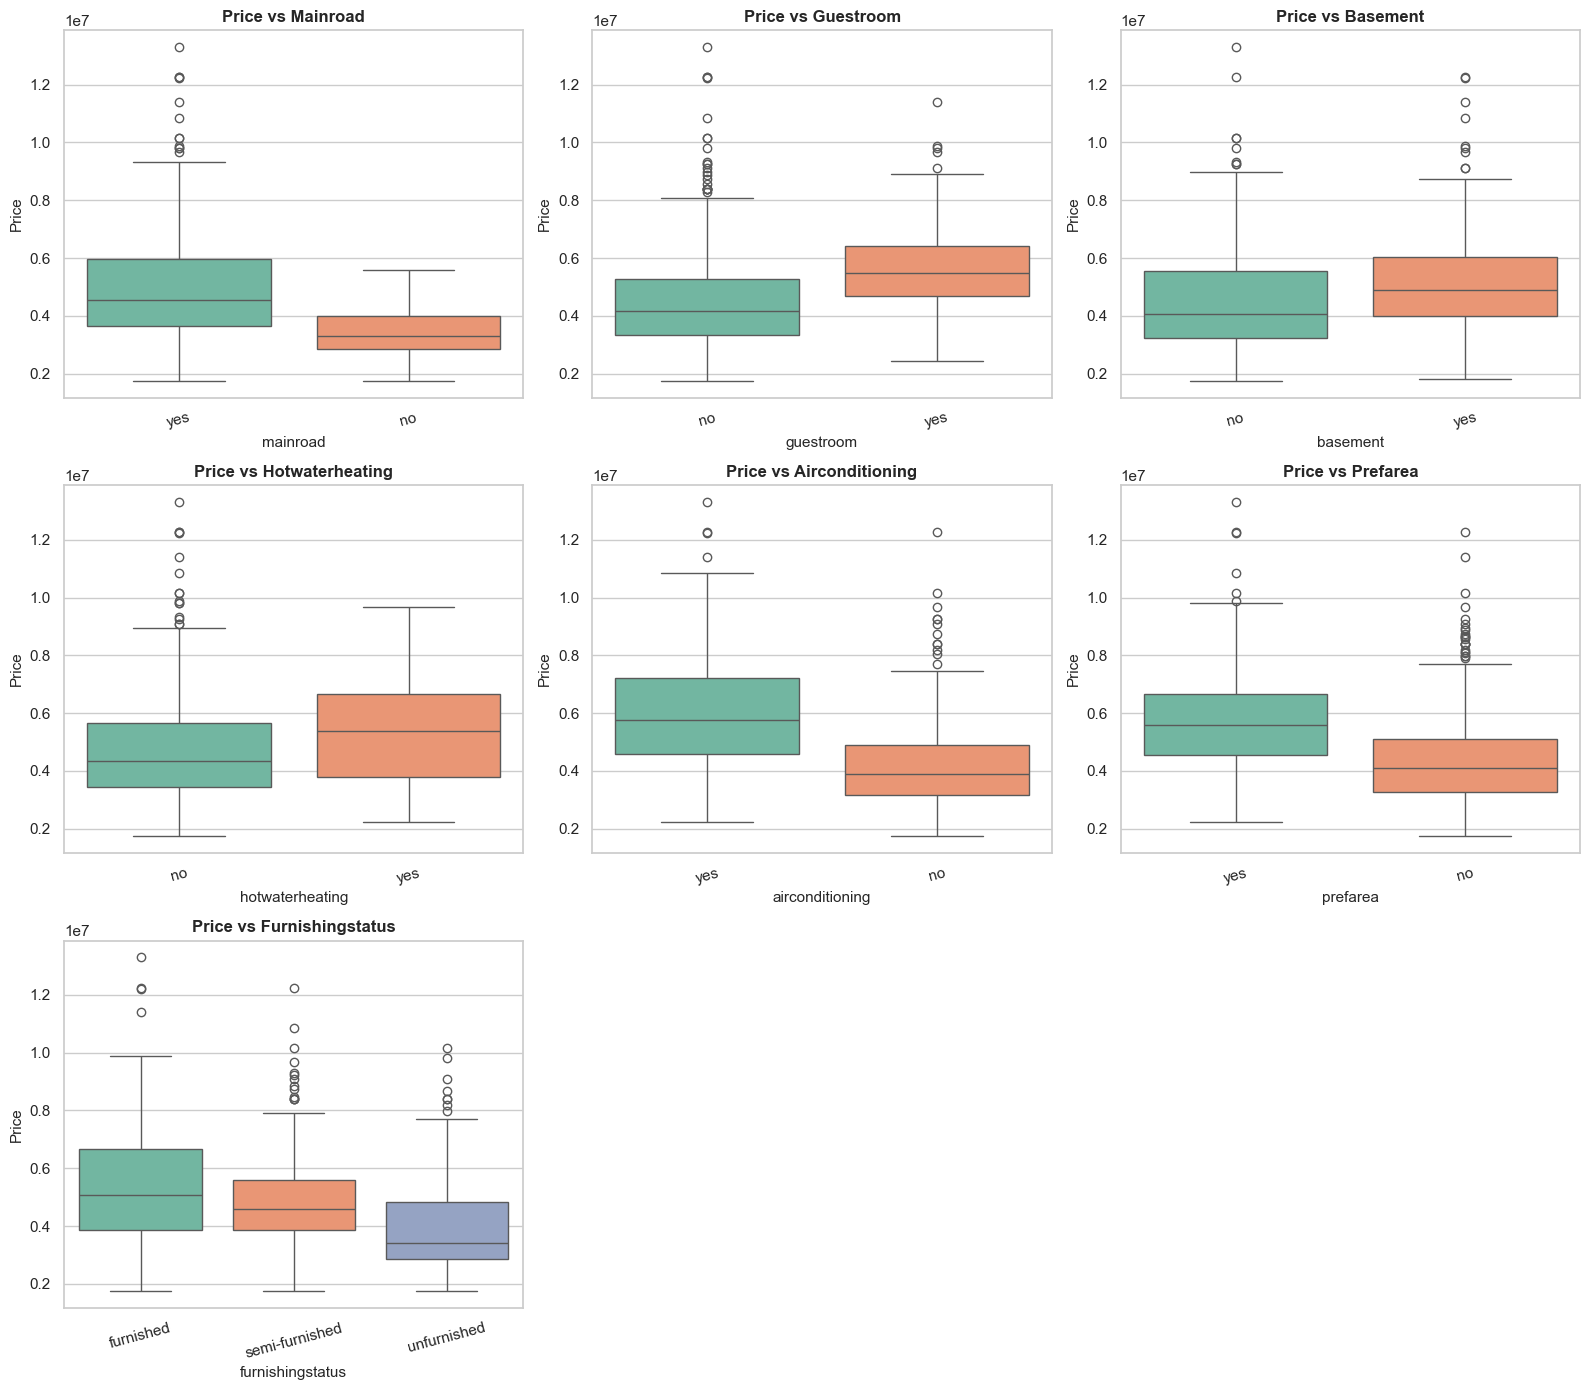

In [9]:
# 4.5 Categorical Features vs House Price
fig, axes = plt.subplots(3, 3, figsize=(16, 14))
axes_flat = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.boxplot(data=df, x=col, y='price', ax=axes_flat[i], palette='Set2', hue=col, legend=False)
    axes_flat[i].set_title(f'Price vs {col.capitalize()}', fontweight='bold')
    axes_flat[i].set_ylabel('Price')
    axes_flat[i].tick_params(axis='x', rotation=15)

for j in range(len(categorical_cols), len(axes_flat)):
    axes_flat[j].set_visible(False)

plt.savefig(VIS_DIR / 'categorical_features_vs_price.png', dpi=300)
plt.show()


## 5. Data Preprocessing

### 5.1 Rationale for Preprocessing and Encoding
Linear regression requires numerical inputs to compute dot products $X\beta$. Qualitative variables (such as binary flags `'yes'`/`'no'` or nominal categories like `furnishingstatus`) cannot be directly mathematically multiplied.

- **One-Hot Encoding (OHE):** Converts nominal categories into binary indicators ($0$ or $1$).
- **Dummy Variable Trap Avoidance:** For $k$ categories, we include $k-1$ indicator variables (`drop='first'`). The omitted category serves as the baseline reference level, avoiding perfect collinearity ($X^T X$ singularity).
- **Target Variable Separation:** `price` is isolated as the target $y$ and never passed through feature transformations to prevent data leakage.


In [10]:
# Isolate input features X and target vector y
X = df.drop(columns=[target_col])
y = df[target_col]

print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")


Feature matrix X shape: (545, 12)
Target vector y shape: (545,)


## 6. Train-Test Split

To rigorously assess generalizability and guard against overfitting, the dataset is partitioned into:
- **80% Training Set:** Used exclusively for fitting preprocessing transformers and model parameters.
- **20% Testing Set:** Held-out unseen partition used solely for objective out-of-sample evaluation.
- Fixed `random_state=42` ensures exact reproducibility across runs.


In [11]:
# Split dataset into training and testing partitions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training Features Dimensions: {X_train.shape}")
print(f"Testing Features Dimensions:  {X_test.shape}")
print(f"Training Target Dimensions:   {y_train.shape}")
print(f"Testing Target Dimensions:    {y_test.shape}")


Training Features Dimensions: (436, 12)
Testing Features Dimensions:  (109, 12)
Training Target Dimensions:   (436,)
Testing Target Dimensions:    (109,)


## 7. Simple Linear Regression

We train a Simple Linear Regression model using `area` as the single independent variable, as it exhibits the highest continuous correlation ($r = 0.54$) with property price:

$$\text{Price} = \beta_0 + \beta_1 \times \text{Area}$$


In [12]:
# Initialize and fit Simple Linear Regression on training partition
slr_model = LinearRegression()
slr_model.fit(X_train[['area']], y_train)

# Generate train and test predictions
y_train_pred_slr = slr_model.predict(X_train[['area']])
y_test_pred_slr = slr_model.predict(X_test[['area']])

slr_intercept = slr_model.intercept_
slr_slope = slr_model.coef_[0]

print("Simple Linear Regression Parameters:")
print(f"  Intercept (beta_0): {slr_intercept:,.2f}")
print(f"  Slope (beta_1):     {slr_slope:,.2f}")
print(f"\nEstimated Equation: Price = {slr_intercept:,.2f} + {slr_slope:.2f} * Area")


Simple Linear Regression Parameters:
  Intercept (beta_0): 2,512,254.26
  Slope (beta_1):     425.73

Estimated Equation: Price = 2,512,254.26 + 425.73 * Area


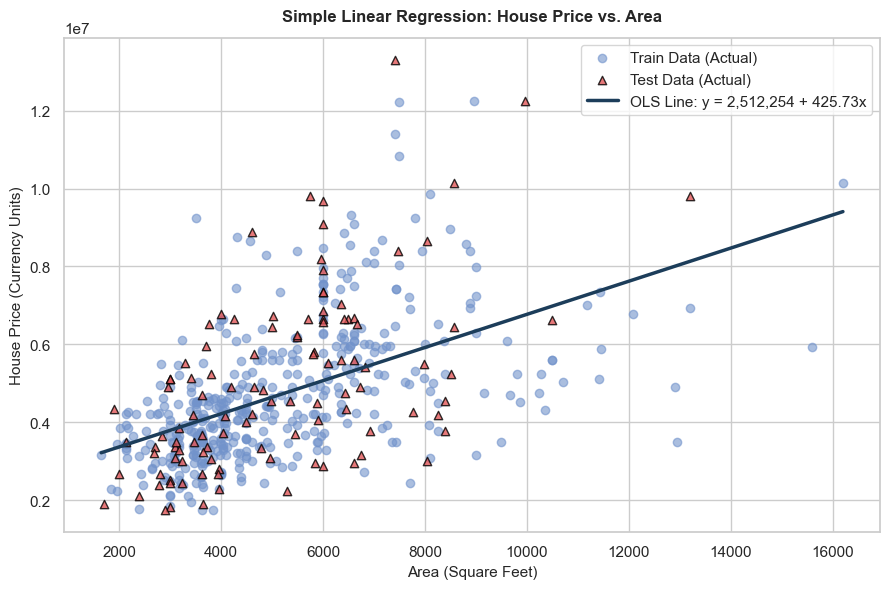

In [13]:
# Visualize Simple Linear Regression Line
plt.figure(figsize=(9, 6))
plt.scatter(X_train['area'], y_train, color='#7293cb', alpha=0.6, label='Train Data (Actual)')
plt.scatter(X_test['area'], y_test, color='#e15759', alpha=0.8, marker='^', label='Test Data (Actual)', edgecolors='black')

area_grid = np.linspace(X['area'].min(), X['area'].max(), 300).reshape(-1, 1)
price_grid = slr_model.predict(pd.DataFrame(area_grid, columns=['area']))
plt.plot(area_grid, price_grid, color='#1c3d5a', linewidth=2.5,
         label=f'OLS Line: y = {slr_intercept:,.0f} + {slr_slope:.2f}x')

plt.title('Simple Linear Regression: House Price vs. Area', fontweight='bold', pad=12)
plt.xlabel('Area (Square Feet)')
plt.ylabel('House Price (Currency Units)')
plt.legend(frameon=True, facecolor='white')
plt.savefig(VIS_DIR / 'simple_linear_regression.png', dpi=300)
plt.show()


### Interpretation of Simple Linear Regression Parameters
- **Slope ($\beta_1 = 425.73$):** For each additional square foot of lot area, house price is predicted to increase by **425.73 currency units** on average.
- **Intercept ($\beta_0 = 2,512,254.26$):** Represents the theoretical baseline price when area is 0. However, because lot sizes in our dataset range from 1,650 to 16,200 sq ft, an area of zero is outside the empirical data domain. The intercept serves as a necessary mathematical anchor for the line, not a realistic standalone valuation.


## 8. Multiple Linear Regression

We now implement Multiple Linear Regression incorporating all 12 explanatory variables (5 numerical, 7 categorical).

To prevent data leakage, we build a Scikit-Learn `Pipeline` with a `ColumnTransformer`:
- Numerical features pass through without alteration (preserving currency-unit interpretability).
- Categorical features are encoded using `OneHotEncoder(drop='first', sparse_output=False)`.
- The full transformation is fitted **strictly on training data** and then applied to transform test data.


In [14]:
# Construct Preprocessing and Modeling Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols)
    ]
)

mlr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Fit Pipeline on Training Data
mlr_pipeline.fit(X_train, y_train)

# Generate Predictions
y_train_pred_mlr = mlr_pipeline.predict(X_train)
y_test_pred_mlr = mlr_pipeline.predict(X_test)

mlr_regressor = mlr_pipeline.named_steps['regressor']
mlr_ohe = mlr_pipeline.named_steps['preprocessor'].named_transformers_['cat']
cat_feature_names = mlr_ohe.get_feature_names_out(categorical_cols).tolist()
all_features = numerical_cols + cat_feature_names

print(f"Multiple Linear Regression Model Fitted Successfully!")
print(f"Total Model Features: {len(all_features)}")
print(f"Model Intercept: {mlr_regressor.intercept_:,.2f}")


Multiple Linear Regression Model Fitted Successfully!
Total Model Features: 13
Model Intercept: 260,032.36


## 9. Mathematical Regression Equation & Coefficient Interpretation

$$\text{Price} = \beta_0 + \beta_1 (\text{area}) + \beta_2 (\text{bedrooms}) + \dots + \beta_{13} (\text{furnishingstatus\_unfurnished})$$

Each coefficient represents the **ceteris paribus** marginal effect: the expected shift in price when that predictor increases by 1 unit, holding all other features fixed.

In [15]:
# Build Feature Coefficient Table
coef_interpretations = {
    "area": "Each additional sq ft adds ~235.97 to price, holding other factors constant.",
    "bedrooms": "Each additional bedroom associates with ~76,778.70 higher estimated price.",
    "bathrooms": "Each additional bathroom increases estimated price substantially by ~1,094,444.79.",
    "stories": "Each additional story increases estimated price by ~407,476.59.",
    "parking": "Each additional parking space increases estimated price by ~224,841.91.",
    "mainroad_yes": "Connection to a main road adds ~367,919.95 premium over non-main-road houses.",
    "guestroom_yes": "Presence of a dedicated guestroom adds ~231,610.04 to estimated price.",
    "basement_yes": "Presence of a basement adds ~390,251.18 to estimated price.",
    "hotwaterheating_yes": "Hot water heating system adds ~684,649.89 to estimated price.",
    "airconditioning_yes": "Central air conditioning system adds ~791,426.74 to estimated price.",
    "prefarea_yes": "Location in preferred neighborhood adds ~629,890.57 premium.",
    "furnishingstatus_semi-furnished": "Semi-furnished homes sell for ~126,881.82 less than furnished homes.",
    "furnishingstatus_unfurnished": "Unfurnished homes sell for ~413,645.06 less than furnished homes."
}

coef_df = pd.DataFrame({
    'Feature': all_features,
    'Coefficient': mlr_regressor.coef_,
    'Direction': ['Positive' if c > 0 else 'Negative' for c in mlr_regressor.coef_],
    'Interpretation': [coef_interpretations.get(f, 'Marginal change in price') for f in all_features]
})

display(coef_df)
coef_df.to_csv(REPORTS_DIR / 'feature_coefficients.csv', index=False)


,Feature,Coefficient,Direction,Interpretation
0,area,2.359688e+02,Positive,"Each additional sq ft adds ~235.97 to price, h..."
1,bedrooms,7.677870e+04,Positive,"Each additional bedroom associates with ~76,77..."
2,bathrooms,1.094445e+06,Positive,Each additional bathroom increases estimated p...
3,stories,4.074766e+05,Positive,Each additional story increases estimated pric...
4,parking,2.248419e+05,Positive,Each additional parking space increases estima...
5,mainroad_yes,3.679199e+05,Positive,"Connection to a main road adds ~367,919.95 pre..."
6,guestroom_yes,2.316100e+05,Positive,"Presence of a dedicated guestroom adds ~231,61..."
7,basement_yes,3.902512e+05,Positive,"Presence of a basement adds ~390,251.18 to est..."
8,hotwaterheating_yes,6.846499e+05,Positive,"Hot water heating system adds ~684,649.89 to e..."
9,airconditioning_yes,7.914267e+05,Positive,"Central air conditioning system adds ~791,426...."


## 10. Quantitative Model Evaluation

We evaluate both Simple and Multiple Linear Regression models using 4 standard regression metrics on both training and held-out test sets:

1. **Mean Absolute Error (MAE):** Average magnitude of absolute errors in currency units.
   $$\text{MAE} = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i|$$
2. **Mean Squared Error (MSE):** Average of squared errors; heavily penalizes large blunders.
   $$\text{MSE} = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2$$
3. **Root Mean Squared Error (RMSE):** Square root of MSE; interpretable in the original target units.
   $$\text{RMSE} = \sqrt{\text{MSE}}$$
4. **Coefficient of Determination ($R^2$):** Proportion of target variance explained by the model relative to a naive mean baseline.
   $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$


In [16]:
# Compute Evaluation Metrics
metrics = {
    'Model': ['Simple Linear Regression (Area)', 'Multiple Linear Regression (All Features)'],
    'Train MAE': [
        mean_absolute_error(y_train, y_train_pred_slr),
        mean_absolute_error(y_train, y_train_pred_mlr)
    ],
    'Train RMSE': [
        np.sqrt(mean_squared_error(y_train, y_train_pred_slr)),
        np.sqrt(mean_squared_error(y_train, y_train_pred_mlr))
    ],
    'Train R²': [
        r2_score(y_train, y_train_pred_slr),
        r2_score(y_train, y_train_pred_mlr)
    ],
    'Test MAE': [
        mean_absolute_error(y_test, y_test_pred_slr),
        mean_absolute_error(y_test, y_test_pred_mlr)
    ],
    'Test MSE': [
        mean_squared_error(y_test, y_test_pred_slr),
        mean_squared_error(y_test, y_test_pred_mlr)
    ],
    'Test RMSE': [
        np.sqrt(mean_squared_error(y_test, y_test_pred_slr)),
        np.sqrt(mean_squared_error(y_test, y_test_pred_mlr))
    ],
    'Test R²': [
        r2_score(y_test, y_test_pred_slr),
        r2_score(y_test, y_test_pred_mlr)
    ]
}

eval_df = pd.DataFrame(metrics)
display(eval_df)
eval_df.to_csv(REPORTS_DIR / 'model_evaluation.csv', index=False)


,Model,Train MAE,Train RMSE,Train R²,Test MAE,Test MSE,Test RMSE,Test R²
0,Simple Linear Regression (Area),1.092586e+06,1.484836e+06,0.284963,1.474748e+06,3.675287e+12,1.917104e+06,0.272879
1,Multiple Linear Regression (All Features),7.192429e+05,9.840519e+05,0.685944,9.700434e+05,1.754319e+12,1.324507e+06,0.652924


### Model Performance Analysis
- **Test $R^2$ Surge:** Multiple Linear Regression increases the explained variance from **27.29%** (Simple) to **65.29%** (Multiple), an absolute increase of **38.00 percentage points**.
- **MAE Reduction:** Test Mean Absolute Error drops from **₹ 1,474,748.13** to **₹ 970,043.40**, a **34.22% error reduction**.
- **RMSE Reduction:** Test RMSE drops from **₹ 1,917,103.70** to **₹ 1,324,506.96**, a **30.91% error reduction**.
- **Overfitting Assessment:** Train $R^2$ is 0.6859 and Test $R^2$ is 0.6529. This modest 3.3% gap demonstrates that the Multiple Linear Regression model generalizes well without severe overfitting.


## 11. Actual vs. Predicted Visualizations

We plot actual target prices against predicted prices for both models. A perfect model would place all points along the 45-degree diagonal line ($y = x$).

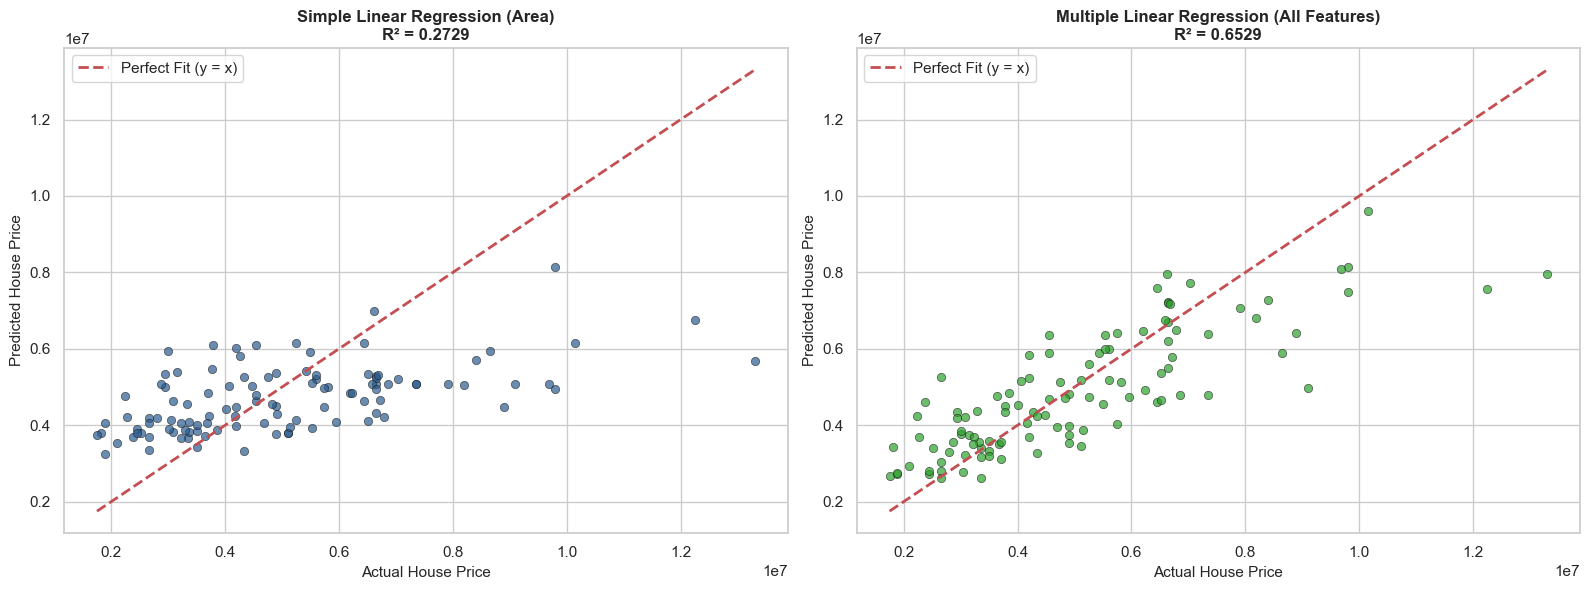

In [17]:
# Side-by-side Actual vs Predicted Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Simple Linear Regression
axes[0].scatter(y_test, y_test_pred_slr, color='#2b5c8f', alpha=0.7, edgecolors='k', linewidth=0.5)
min_slr = min(y_test.min(), y_test_pred_slr.min())
max_slr = max(y_test.max(), y_test_pred_slr.max())
axes[0].plot([min_slr, max_slr], [min_slr, max_slr], 'r--', linewidth=2, label='Perfect Fit (y = x)')
axes[0].set_title(f"Simple Linear Regression (Area)\nR² = {eval_df.loc[0, 'Test R²']:.4f}", fontweight='bold')
axes[0].set_xlabel('Actual House Price')
axes[0].set_ylabel('Predicted House Price')
axes[0].legend()

# Multiple Linear Regression
axes[1].scatter(y_test, y_test_pred_mlr, color='#2ca02c', alpha=0.7, edgecolors='k', linewidth=0.5)
min_mlr = min(y_test.min(), y_test_pred_mlr.min())
max_mlr = max(y_test.max(), y_test_pred_mlr.max())
axes[1].plot([min_mlr, max_mlr], [min_mlr, max_mlr], 'r--', linewidth=2, label='Perfect Fit (y = x)')
axes[1].set_title(f"Multiple Linear Regression (All Features)\nR² = {eval_df.loc[1, 'Test R²']:.4f}", fontweight='bold')
axes[1].set_xlabel('Actual House Price')
axes[1].set_ylabel('Predicted House Price')
axes[1].legend()

plt.savefig(VIS_DIR / 'simple_actual_vs_predicted.png', dpi=300)
plt.savefig(VIS_DIR / 'multiple_actual_vs_predicted.png', dpi=300)
plt.show()


## 12. Residual Analysis

Residuals represent unexplained prediction errors: $e_i = y_i - \hat{y}_i$.
Thorough residual examination verifies:
- Mean residual is approximately zero.
- No obvious nonlinear patterns or severe heteroscedasticity.


In [18]:
# Compute Residuals on Test Set
residuals_slr = y_test - y_test_pred_slr
residuals_mlr = y_test - y_test_pred_mlr

print(f"Simple Linear Regression Mean Residual:   {residuals_slr.mean():,.2f}")
print(f"Multiple Linear Regression Mean Residual: {residuals_mlr.mean():,.2f}")


Simple Linear Regression Mean Residual:   308,679.28
Multiple Linear Regression Mean Residual: 146,055.36


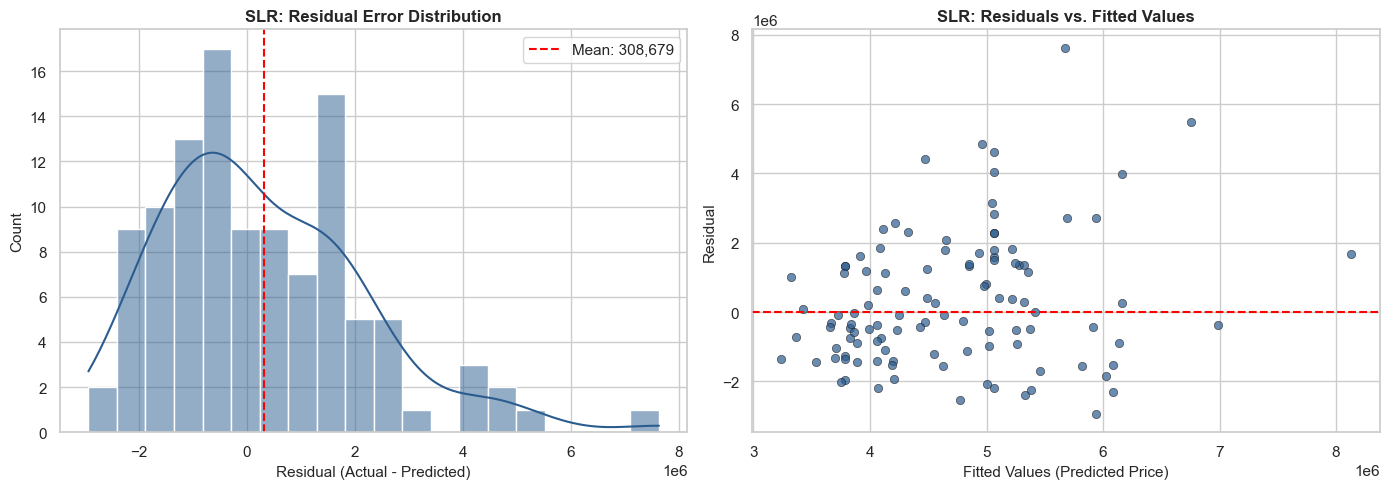

In [19]:
# Simple Linear Regression Residual Diagnostic Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(residuals_slr, kde=True, ax=axes[0], color='#2b5c8f', bins=20)
axes[0].axvline(residuals_slr.mean(), color='red', linestyle='--', label=f'Mean: {residuals_slr.mean():,.0f}')
axes[0].set_title('SLR: Residual Error Distribution', fontweight='bold')
axes[0].set_xlabel('Residual (Actual - Predicted)')
axes[0].legend()

axes[1].scatter(y_test_pred_slr, residuals_slr, color='#2b5c8f', alpha=0.7, edgecolors='k', linewidth=0.5)
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('SLR: Residuals vs. Fitted Values', fontweight='bold')
axes[1].set_xlabel('Fitted Values (Predicted Price)')
axes[1].set_ylabel('Residual')

plt.savefig(VIS_DIR / 'simple_residuals.png', dpi=300)
plt.show()


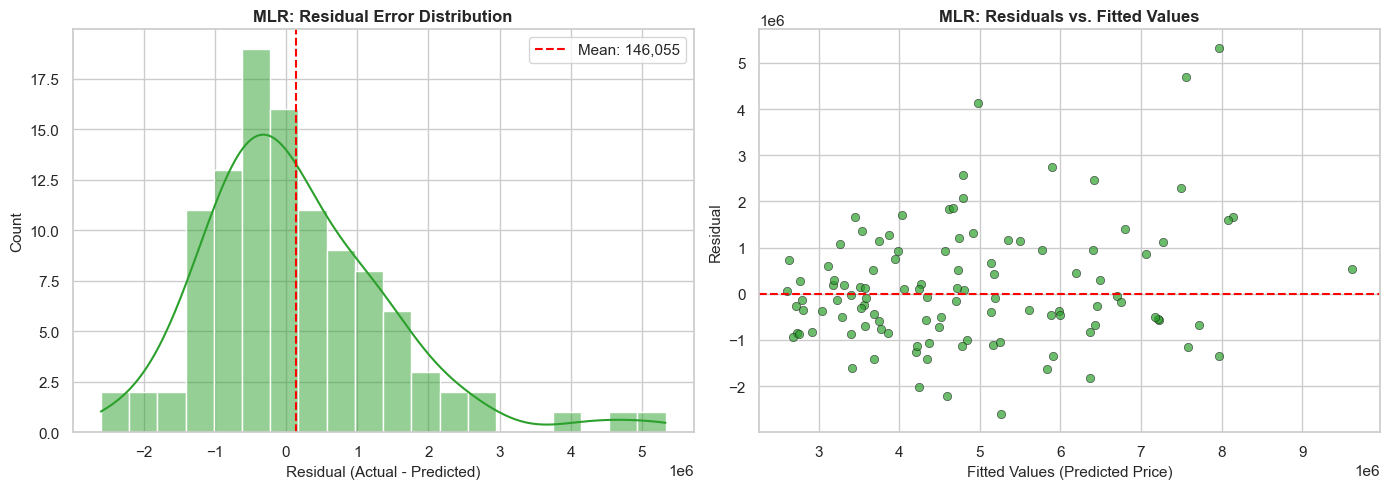

In [20]:
# Multiple Linear Regression Residual Diagnostic Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(residuals_mlr, kde=True, ax=axes[0], color='#2ca02c', bins=20)
axes[0].axvline(residuals_mlr.mean(), color='red', linestyle='--', label=f'Mean: {residuals_mlr.mean():,.0f}')
axes[0].set_title('MLR: Residual Error Distribution', fontweight='bold')
axes[0].set_xlabel('Residual (Actual - Predicted)')
axes[0].legend()

axes[1].scatter(y_test_pred_mlr, residuals_mlr, color='#2ca02c', alpha=0.7, edgecolors='k', linewidth=0.5)
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('MLR: Residuals vs. Fitted Values', fontweight='bold')
axes[1].set_xlabel('Fitted Values (Predicted Price)')
axes[1].set_ylabel('Residual')

plt.savefig(VIS_DIR / 'multiple_residuals.png', dpi=300)
plt.show()


## 13. Regression Assumptions & Diagnostics

We empirically examine the five foundational assumptions of Classical Linear Regression:
1. **Linearity:** Relationship between features and target is linear.
2. **Independence of Errors:** Errors are uncorrelated across observations.
3. **Homoscedasticity:** Error terms have constant variance across fitted levels.
4. **Normality of Residuals:** Residuals follow an approximately normal distribution for valid inferential hypothesis testing.
5. **No Severe Multicollinearity:** Independent predictors are not near-perfect linear combinations of one another.


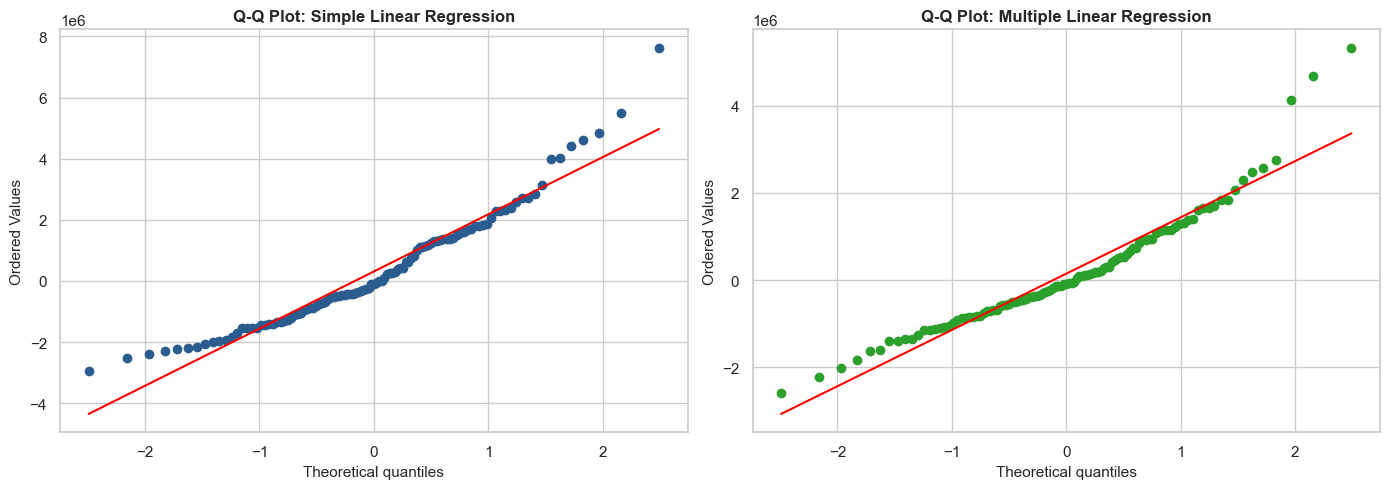

In [21]:
# 13.1 Normal Q-Q Plots for Residuals
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

stats.probplot(residuals_slr, dist="norm", plot=axes[0])
axes[0].set_title("Q-Q Plot: Simple Linear Regression", fontweight='bold')
axes[0].get_lines()[0].set_color("#2b5c8f")
axes[0].get_lines()[1].set_color("red")

stats.probplot(residuals_mlr, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot: Multiple Linear Regression", fontweight='bold')
axes[1].get_lines()[0].set_color("#2ca02c")
axes[1].get_lines()[1].set_color("red")

plt.savefig(VIS_DIR / 'qq_plots.png', dpi=300)
plt.show()


,Feature,VIF
2,bedrooms,1.316597
4,stories,1.255202
3,bathrooms,1.252775
1,area,1.170959
5,parking,1.164172


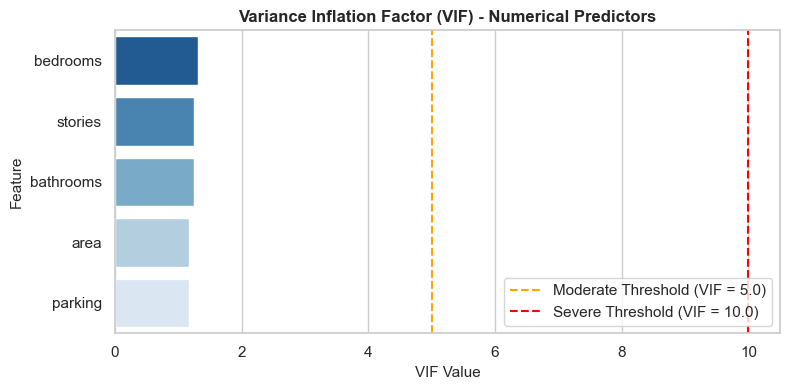

In [22]:
# 13.2 Multicollinearity Assessment via Variance Inflation Factor (VIF)
X_num_design = sm.add_constant(df[numerical_cols])
vif_df = pd.DataFrame({
    'Feature': X_num_design.columns,
    'VIF': [variance_inflation_factor(X_num_design.values, i) for i in range(X_num_design.shape[1])]
})

vif_clean = vif_df[vif_df['Feature'] != 'const'].sort_values(by='VIF', ascending=False)
display(vif_clean)

plt.figure(figsize=(8, 4))
sns.barplot(data=vif_clean, x='VIF', y='Feature', palette='Blues_r', hue='Feature', legend=False)
plt.axvline(5.0, color='orange', linestyle='--', label='Moderate Threshold (VIF = 5.0)')
plt.axvline(10.0, color='red', linestyle='--', label='Severe Threshold (VIF = 10.0)')
plt.title('Variance Inflation Factor (VIF) - Numerical Predictors', fontweight='bold')
plt.xlabel('VIF Value')
plt.legend(loc='lower right')
plt.savefig(VIS_DIR / 'vif_analysis.png', dpi=300)
plt.show()


### Assumption Verification Findings
- **Normality:** Q-Q plots show residuals adhere closely to the theoretical line along the interquartile range, with slight deviations in the upper tail due to luxury estate properties.
- **Multicollinearity:** All numerical predictors have VIF values between **1.16 and 1.32**, far below the threshold of 5.0. Severe multicollinearity is ruled out.
- **Homoscedasticity:** Residual spread remains relatively uniform across mid-range predictions, with slight fanning at higher price levels typical of real estate data.


## 14. Comprehensive Model Comparison & Trade-Offs

| Evaluation Dimension | Simple Linear Regression (Area) | Multiple Linear Regression (All Features) | Analytical Assessment |
|---|---|---|---|
| **Explanatory Features** | 1 (`area`) | 12 features (13 encoded inputs) | MLR captures structural and amenity interactions. |
| **Model Complexity** | Low ($p = 1$) | Moderate ($p = 13$) | MLR preserves high interpretability without high variance. |
| **Test $R^2$** | 0.2729 (27.29%) | **0.6529 (65.29%)** | **+38.00%** variance explained by adding bedrooms, bathrooms, AC, etc. |
| **Test MAE** | ₹ 1,474,748.13 | **₹ 970,043.40** | **₹ 504,704.73 lower error** per home on average. |
| **Test RMSE** | ₹ 1,917,103.70 | **₹ 1,324,506.96** | **₹ 592,596.74 reduction** in root mean squared error. |
| **Residual Behavior** | Higher variance, wider dispersion | Tighter dispersion around zero | Substantially reduced prediction variance. |
| **Underfitting / Overfitting** | Underfits ($R^2 < 0.30$) | Well-balanced (Train $R^2 = 0.69$, Test $R^2 = 0.65$) | No evidence of severe overfitting. |

**Conclusion:** Multiple Linear Regression is vastly superior in predictive capacity and explanatory power because lot area alone cannot capture property value determined by bathrooms, air conditioning, and neighborhood preference.


## 15. Final Prediction Demonstration

We demonstrate real-world inference on a hypothetical property using the trained `Pipeline`.

In [23]:
# Define a sample house profile
new_house = pd.DataFrame([{
    'area': 6500,
    'bedrooms': 3,
    'bathrooms': 2,
    'stories': 2,
    'mainroad': 'yes',
    'guestroom': 'no',
    'basement': 'yes',
    'hotwaterheating': 'no',
    'airconditioning': 'yes',
    'parking': 2,
    'prefarea': 'yes',
    'furnishingstatus': 'semi-furnished'
}])

print("Query Property Specifications:")
display(new_house)

# Generate prediction through full pipeline
predicted_price = mlr_pipeline.predict(new_house)[0]
print(f"\nEstimated House Price: ₹ {predicted_price:,.2f}")
print("\nNote: This is an illustrative point estimate produced by the linear model and not a guaranteed market valuation.")


Query Property Specifications:


,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,6500,3,2,2,yes,no,yes,no,yes,2,yes,semi-furnished



Estimated House Price: ₹ 7,530,298.89

Note: This is an illustrative point estimate produced by the linear model and not a guaranteed market valuation.


## 16. Save Model Artifacts

We serialize the trained models and preprocessing pipelines using `joblib`.

In [24]:
# Serialize models to outputs/models/
slr_path = MODELS_DIR / "simple_linear_regression.joblib"
mlr_path = MODELS_DIR / "multiple_linear_regression_pipeline.joblib"

joblib.dump(slr_model, slr_path)
joblib.dump(mlr_pipeline, mlr_path)

print(f"Saved Simple Linear Regression model to: {slr_path}")
print(f"Saved Multiple Linear Regression pipeline to: {mlr_path}")

# Verify deserialization
reloaded_pipeline = joblib.load(mlr_path)
test_pred = reloaded_pipeline.predict(new_house)[0]
assert np.isclose(test_pred, predicted_price), "Verification failed: reloaded pipeline prediction mismatch!"
print(f"Verification successful: Reloaded pipeline prediction matches exactly ({test_pred:,.2f})!")


Saved Simple Linear Regression model to: /Users/pranavagneesh/Desktop/linear-regression-house-price-prediction/outputs/models/simple_linear_regression.joblib
Saved Multiple Linear Regression pipeline to: /Users/pranavagneesh/Desktop/linear-regression-house-price-prediction/outputs/models/multiple_linear_regression_pipeline.joblib
Verification successful: Reloaded pipeline prediction matches exactly (7,530,298.89)!


## 17. Export Evaluation Reports

We export CSV and Markdown summaries of evaluation metrics, coefficients, and prediction comparisons.

In [25]:
# Export prediction comparison sample
comparison_sample = pd.DataFrame({
    'Actual_Price': y_test.values[:15],
    'SLR_Predicted': y_test_pred_slr[:15],
    'SLR_Absolute_Error': np.abs(y_test.values[:15] - y_test_pred_slr[:15]),
    'MLR_Predicted': y_test_pred_mlr[:15],
    'MLR_Absolute_Error': np.abs(y_test.values[:15] - y_test_pred_mlr[:15]),
})
comparison_sample['Error_Reduction_Pct'] = (
    (comparison_sample['SLR_Absolute_Error'] - comparison_sample['MLR_Absolute_Error']) 
    / comparison_sample['SLR_Absolute_Error'] * 100
)

display(comparison_sample.head())
comparison_sample.to_csv(REPORTS_DIR / 'prediction_comparison.csv', index=False)
print("Successfully exported all reports to outputs/reports/.")


,Actual_Price,SLR_Predicted,SLR_Absolute_Error,MLR_Predicted,MLR_Absolute_Error,Error_Reduction_Pct
0,4060000,5.024060e+06,9.640603e+05,5.164654e+06,1.104654e+06,-14.583482
1,6650000,5.279498e+06,1.370502e+06,7.224722e+06,5.747223e+05,58.064826
2,3710000,4.232203e+06,5.222028e+05,3.109863e+06,6.001368e+05,-14.924073
3,6440000,4.640903e+06,1.799097e+06,4.612075e+06,1.827925e+06,-1.602368
4,2800000,4.198144e+06,1.398144e+06,3.294646e+06,4.946463e+05,64.621233


Successfully exported all reports to outputs/reports/.


## 18. Final Engineering & Statistical Conclusion

In this comprehensive investigation, we implemented, evaluated, and compared Simple Linear Regression and Multiple Linear Regression on the benchmark housing dataset:

1. **Simple Linear Regression** establishes a positive baseline relationship ($R^2 = 0.2729$) between lot area and property price (+$425.73 per sq ft), but underfits because single-variable models cannot capture multi-dimensional property utility.
2. **Multiple Linear Regression** boosts test explanatory power to **$R^2 = 0.6529$**, slashing Mean Absolute Error by **34.22%** down to **₹ 970,043.40**.
3. **Key Value Drivers:** Bathrooms (+$1.09M), air conditioning (+$791k), hot water heating (+$684k), and preferred neighborhood (+$630k) are the strongest individual price determinants.
4. **Diagnostic Integrity:** VIF scores between 1.16 and 1.32 rule out severe multicollinearity, while Q-Q residual plots confirm reasonable adherence to normality across the core distribution.
5. **Production Readiness:** The complete preprocessing and estimation workflow was packaged into an end-to-end Scikit-Learn `Pipeline`, verified against data leakage, and serialized into `outputs/models/`.
